<p style="text-align:center"><img src="images/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Capstone: A Cloud Web-GIS for Flood Monitoring in the Haor Basin

The haor basin of north-eastern Bangladesh floods every monsoon. For about half the year its
wetlands and rice fields lie under water; in the dry season farmers grow Boro rice, the region's
main crop, and an early flash flood before harvest can destroy it. District officers, NGOs and
researchers need to know **where water is, union by union, through the year**, in a form they can
open in a browser or pull into their own tools.

This capstone builds that system end to end with the methods of Module 08, for the haors around
Tanguar Haor and Sunamganj town in 2024:

| Step | What | From notebook |
|---|---|---|
| Find data | Sentinel-1 radar (sees through monsoon clouds) from a STAC catalogue | 07_01, 07_09 |
| Process | Water maps every 12 days, flood frequency, statistics per union | 07_08 |
| Validate | Against Sentinel-2 (Notebook 07_10's monitor) and the JRC 1984-2020 water record | 07_09, 07_10 |
| Store | Cloud-optimised GeoTIFFs, GeoParquet, a STAC catalogue | 07_01, 07_02 |
| Serve | Tiles and OGC API: Features (`geolattice.web`) inside a FastAPI service with its own endpoints | 07_05, 07_06 |
| Show | A web map that calls the API | 07_04, 07_07 |
| Operate | Idempotent updates, tests, deployment checklist | 07_10 |



### Data

| Data | Source |
|---|---|
| Sentinel-1 radiometrically terrain-corrected (RTC) backscatter, 2024, ascending track 41 | Planetary Computer `sentinel-1-rtc` |
| JRC Global Surface Water occurrence 1984-2020 | Planetary Computer `jrc-gsw` |
| Union boundaries of Bangladesh | `Data/00_shared/vector_data/Bangladesh/Shapefiles/bd_union_GCS.shp` |
| Sentinel-2 water fractions of Tanguar Haor, 2024 | `Data/00_shared/data_web_cloud_gis/08_10_outputs/monitor_data/observations.parquet` (Notebook 08_10, optional) |



### Contents

1. Setup
2. Architecture
3. Data: Sentinel-1 over the haors
4. Water from radar: choosing the threshold
5. Processing 2024: water maps every 12 days
6. Flood frequency and statistics per union
7. Validation
8. Storage: COGs, GeoParquet and a STAC catalogue
9. The service: FastAPI with OGC endpoints, tiles and a web map
10. Tests and operations
11. Summary: from data to decisions


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `fastapi`, which no GeoLattice option installs: `pip install fastapi`.

In [1]:
# Imports, AOI parameters, and Planetary Computer client for the capstone
%matplotlib inline
import difflib
import json
import shutil
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import rasterio
from rasterio.features import rasterize
import matplotlib.pyplot as plt
import pystac
import pystac_client
import planetary_computer
import odc.stac
from fastapi import FastAPI, HTTPException, Query
from fastapi.middleware.gzip import GZipMiddleware
from fastapi.responses import HTMLResponse
from fastapi.staticfiles import StaticFiles
from fastapi.testclient import TestClient
from IPython.display import IFrame, display

import geolattice
import geolattice.web as web
from geolattice.vector import write_geoparquet, read_geoparquet

plt.rcParams.update({"figure.dpi": 110})
DATA = Path("../../../Data")
BD = DATA / "00_shared" / "vector_data" / "Bangladesh"
WEB = DATA / "00_shared" / "data_web_cloud_gis"
OUT = WEB / "08_11_outputs"
# Fresh output tree; water masks land in OUT/water
if OUT.exists():
    shutil.rmtree(OUT)
(OUT / "water").mkdir(parents=True)

AOI = (90.95, 24.95, 91.25, 25.20)          # ~30 x 28 km: Tanguar Haor, Sunamganj town and surrounding haors
CRS, RES = "EPSG:32646", 30                   # UTM 46N, 30 m
YEAR = 2024
TRACK = 41                                     # Sentinel-1 relative orbit (ascending): one viewing geometry
THRESHOLD_DB = -20.0                           # VH backscatter below this is open water (Section 4)
VV_THRESHOLD_DB = -18.0                        # the common VV rule, kept for comparison
pcc = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
print("geolattice", geolattice.__version__, "| outputs:", OUT)


geolattice 0.3.11 | outputs: ../../../data/data_web_cloud_gis/08_11_outputs


## Architecture

```text
 Planetary Computer (STAC + COGs)            Processing (this notebook / a scheduled container)
 ┌─────────────────────────────┐   search    ┌──────────────────────────────────────────────┐
 │ sentinel-1-rtc  jrc-gsw     │ ──────────► │ odc-stac load → dB → water mask (VH < −20 dB)│
 └─────────────────────────────┘   read      │ per-union statistics, flood frequency        │
                                             └───────────────┬──────────────────────────────┘
                                                             │ write (idempotent)
                        Storage (object storage in production)▼
                ┌──────────────────────────────────────────────────────────────┐
                │ water/*.tif (COG) · flood_frequency.tif (COG)                │
                │ unions_flood.parquet (GeoParquet) · union_series.parquet     │
                │ stac/catalog.json (STAC)                                     │
                └───────────────┬───────────────────────────────┬──────────────┘
                                │                               │
          Service (FastAPI + geolattice.web)                  Any STAC / GIS client
   /ogc  tiles + OGC API Features (geolattice.web.create_app)   (QGIS, GDAL, STAC Browser)
   /api  dates, union time series, rankings
   /map  web map (Leaflet) calling /ogc and /api
```

Processing writes files; the service only reads them. Each part can be replaced or scaled without
touching the others: the files can move to S3 or Azure Blob, the service can run in several
containers behind a load balancer, and the processing can run on a schedule (Notebook 08_10).

## Data: Sentinel-1 over the haors

Radar sees through cloud, so it observes the haors throughout the monsoon, when Sentinel-2 saw
nothing usable (Notebook 08_10). Open water reflects the radar pulse away from the satellite and
appears dark. We use the **RTC** product (backscatter normalised for terrain) and a single relative
orbit, so that every acquisition has the same viewing geometry and the time series is comparable.

In [2]:
# Search Sentinel-1 RTC for the year and summarize orbits and revisit gaps
t0 = time.perf_counter()
items = list(pcc.search(collections=["sentinel-1-rtc"], bbox=list(AOI), datetime=f"{YEAR}-01-01/{YEAR}-12-31").items())
tracks = pd.DataFrame([{"track": i.properties["sat:relative_orbit"], "direction": i.properties["sat:orbit_state"],
                        "platform": i.properties["platform"], "date": i.datetime.date()} for i in items])
print(f"{len(items)} Sentinel-1 RTC items over the area in {YEAR} ({time.perf_counter() - t0:.1f} s)")
display(tracks.groupby(["track", "direction", "platform"]).date.agg(["count", "nunique", "min", "max"])
        .rename(columns={"count": "items", "nunique": "dates"}))
# Keep only the chosen relative orbit so geometry stays consistent
by_day = {}
for i in items:
    if i.properties["sat:relative_orbit"] == TRACK:
        by_day.setdefault(i.datetime.date(), []).append(i)
dates = sorted(by_day)
gaps = np.diff(pd.to_datetime(dates)).astype("timedelta64[D]").astype(int)
print(f"track {TRACK}: {len(dates)} dates, gaps between acquisitions: {sorted(set(gaps))} days")


146 Sentinel-1 RTC items over the area in 2024 (1.5 s)


,,,items,dates,min,max
track,direction,platform,,,,
41,ascending,SENTINEL-1A,56,29,2024-01-01,2024-12-26
77,descending,SENTINEL-1A,25,25,2024-01-03,2024-12-04
114,ascending,SENTINEL-1A,26,26,2024-01-06,2024-12-19
150,descending,SENTINEL-1A,39,21,2024-01-20,2024-12-21


track 41: 29 dates, gaps between acquisitions: [np.int64(12), np.int64(24)] days


Planetary Computer holds 146 Sentinel-1 RTC items over the area for 2024, on four relative orbits,
all from Sentinel-1A (Sentinel-1B failed in December 2021). Ascending track 41 covers the area on 29
dates, every 12 days, with one 24-day gap where an acquisition is missing. Two adjacent frames
make up each date and are mosaicked by date.

## Water from radar: choosing the band and the threshold

Calm open water reflects the radar pulse away from the satellite, so it is dark in both
polarisations: co-polarised VV and cross-polarised VH. Wind and waves roughen the water surface and
brighten VV much more than VH. The haors are large, shallow and windy in the monsoon, so we compare
both bands on a dry-season and a flood-season date before choosing.

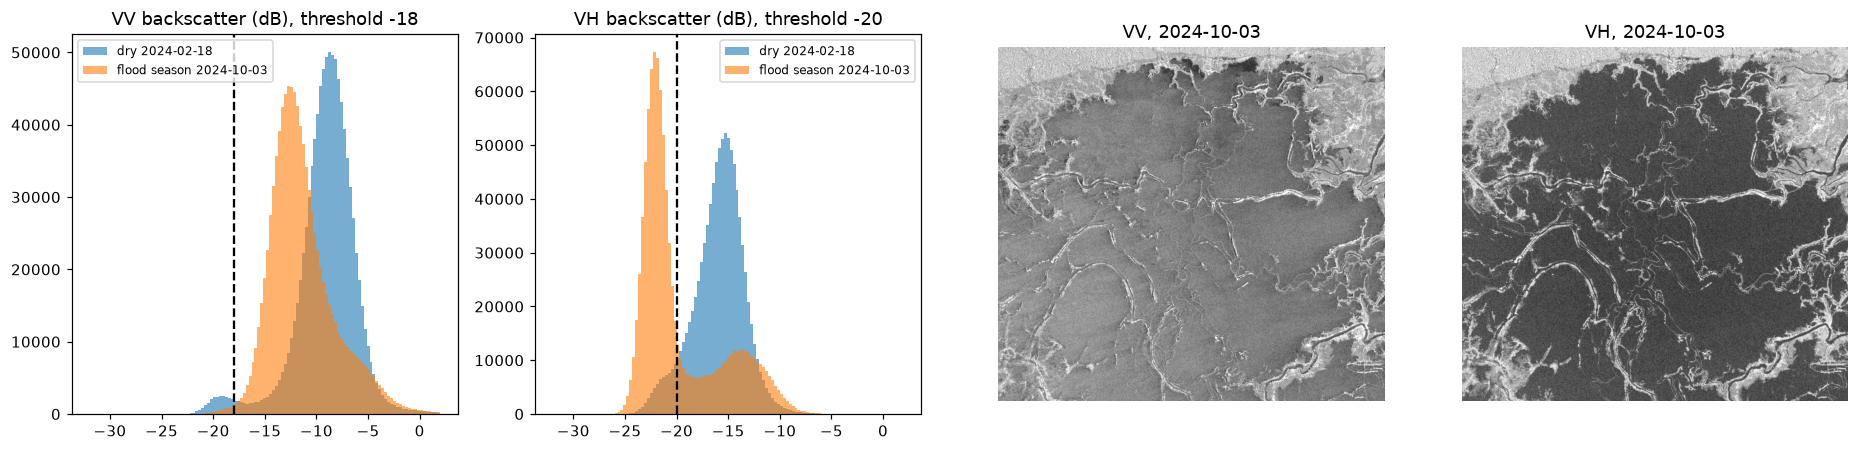

share of the area classified as water (%):


,VV < -20,VV < -18,VV < -16,VH < -22,VH < -21,VH < -20,VH < -19,VH < -18
dry 2024-02-18,0.7,2.4,3.6,1.8,4.1,7.1,11.6,18.5
flood season 2024-10-03,0.1,0.6,3.1,35.3,56.2,65.8,69.5,72.0


In [3]:
# Load VV/VH in dB for dry and flood-season dates; compare water thresholds
def load_db(day):
    "VV and VH backscatter in dB for one acquisition date on the 30 m AOI grid (average resampling reduces speckle)."
    ds = odc.stac.load(by_day[day], bands=["vv", "vh"], bbox=list(AOI), crs=CRS, resolution=RES, groupby="solar_day",
                       resampling="average").isel(time=0)
    out = {}
    for band in ["vv", "vh"]:
        v = ds[band].values.astype("float32")
        with np.errstate(divide="ignore", invalid="ignore"):
            out[band] = np.where(v > 0, 10 * np.log10(v), np.nan)
    return out, ds.odc.geobox

dry = min(dates, key=lambda d: abs((pd.Timestamp(d) - pd.Timestamp(f"{YEAR}-02-15")).days))
wet = min(dates, key=lambda d: abs((pd.Timestamp(d) - pd.Timestamp(f"{YEAR}-10-03")).days))
db_dry, geobox = load_db(dry)
db_wet, _ = load_db(wet)
# Histograms and grayscale maps, then a small threshold sensitivity table
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
for a, band, thr in [(ax[0], "vv", VV_THRESHOLD_DB), (ax[1], "vh", THRESHOLD_DB)]:
    bins = np.linspace(-32, 2, 120)
    a.hist(db_dry[band][np.isfinite(db_dry[band])], bins=bins, alpha=0.6, label=f"dry {dry}")
    a.hist(db_wet[band][np.isfinite(db_wet[band])], bins=bins, alpha=0.6, label=f"flood season {wet}")
    a.axvline(thr, color="k", ls="--"); a.set_title(f"{band.upper()} backscatter (dB), threshold {thr:g}"); a.legend(fontsize=8)
for a, band in [(ax[2], "vv"), (ax[3], "vh")]:
    a.imshow(db_wet[band], cmap="gray", vmin=-28 if band == "vh" else -25, vmax=-8 if band == "vh" else 0)
    a.set_title(f"{band.upper()}, {wet}"); a.set_axis_off()
plt.tight_layout(); plt.show()
sens = pd.DataFrame({
    **{f"VV < {t}": [np.nanmean(db_dry["vv"] < t), np.nanmean(db_wet["vv"] < t)] for t in [-20, -18, -16]},
    **{f"VH < {t}": [np.nanmean(db_dry["vh"] < t), np.nanmean(db_wet["vh"] < t)] for t in [-22, -21, -20, -19, -18]}},
    index=[f"dry {dry}", f"flood season {wet}"])
print("share of the area classified as water (%):")
(sens * 100).round(1)


The dry and flood scenes behave very differently in the two bands:

| Rule | Dry season, 18 February | Flood season, 3 October |
|---|---|---|
| VV < −18 dB | 2.4% water | 0.6% water |
| VH < −20 dB | 7.1% water | 65.8% water |

On 3 October the haors were full, yet VV classified only 0.6% of the area as water: the images
show the open water grey and textured in VV, roughened by wind, and uniformly dark in VH. VH
separates the two seasons cleanly. Its water mode sits near −22 dB, close to the sensor's noise
floor, and its land mode is around −15 dB. A threshold of −20 dB lies between them; moving it by
±1 dB changes the flood-season estimate by about 4-10 points.

## Processing 2024: water maps every 12 days

For each acquisition the processing step loads VV and VH, classifies water from VH, and writes a
small Cloud-Optimised GeoTIFF (1 = water, 0 = land, 255 = no data), plus a JSON sidecar with the
area's water share under both rules. It skips dates whose COG already
exists, so rerunning it, or running it on a schedule, only processes new acquisitions.

In [4]:
# Write an idempotent water-mask COG for every acquisition date
def water_path(day):
    return OUT / "water" / f"water_{day}.tif"

def process_day(day):
    "Water mask for one date as a COG; skipped if it exists (idempotent)."
    path = water_path(day)
    if path.exists():
        return "skipped"
    db, gb = load_db(day)
    ok = np.isfinite(db["vh"])
    mask = np.where(ok, (db["vh"] < THRESHOLD_DB).astype("uint8"), 255).astype("uint8")
    path.with_suffix(".json").write_text(json.dumps({
        "valid_pct": float(ok.mean() * 100), "vh_water_pct": float(np.nanmean(db["vh"][ok] < THRESHOLD_DB) * 100),
        "vv_water_pct": float(np.nanmean(db["vv"][np.isfinite(db["vv"])] < VV_THRESHOLD_DB) * 100),
        "median_vv_db": float(np.nanmedian(db["vv"])), "median_vh_db": float(np.nanmedian(db["vh"]))}))
    tmp = path.with_suffix(".tmp.tif")
    with rasterio.open(tmp, "w", driver="GTiff", width=mask.shape[1], height=mask.shape[0], count=1, dtype="uint8",
                       crs=CRS, transform=gb.affine, nodata=255) as dst:
        dst.write(mask, 1)
    web.to_cog(tmp, path, compress="DEFLATE", overview_resampling="NEAREST")
    tmp.unlink()
    return "processed"

# First pass processes; second pass should skip existing COGs
t0 = time.perf_counter()
status = {d: process_day(d) for d in dates}
first_run = time.perf_counter() - t0
t0 = time.perf_counter()
status_again = {d: process_day(d) for d in dates}
second_run = time.perf_counter() - t0
print(f"first run: {list(status.values()).count('processed')} dates processed in {first_run:.0f} s; "
      f"second run: {list(status_again.values()).count('skipped')} skipped in {second_run:.2f} s")
cogs = sorted((OUT / "water").glob("*.tif"))
print(f"{len(cogs)} COGs, {sum(p.stat().st_size for p in cogs) / 1e6:.1f} MB in total;", web.validate_cog(cogs[0]))
rules = pd.DataFrame([json.loads(water_path(d).with_suffix(".json").read_text()) for d in dates], index=pd.to_datetime(dates))
monsoon = rules.loc[f"{YEAR}-06-01":f"{YEAR}-10-31"]
print("monsoon (June-October) water share, % of area:")
display(pd.DataFrame({rule: {"min": monsoon[c].min(), "max": monsoon[c].max(),
                             "mean absolute change between acquisitions": monsoon[c].diff().abs().mean()}
                      for rule, c in [(f"VV < {VV_THRESHOLD_DB:g} dB", "vv_water_pct"), (f"VH < {THRESHOLD_DB:g} dB", "vh_water_pct")]}).T.round(1))
print(f"median VV over the area ranged from {monsoon.median_vv_db.min():.1f} to {monsoon.median_vv_db.max():.1f} dB in the monsoon; "
      f"median VH from {monsoon.median_vh_db.min():.1f} to {monsoon.median_vh_db.max():.1f} dB")


first run: 29 dates processed in 294 s; second run: 29 skipped in 0.00 s
29 COGs, 2.0 MB in total; ../../../data/data_web_cloud_gis/08_11_outputs/water/water_2024-01-01.tif: valid Cloud-Optimized GeoTIFF
monsoon (June-October) water share, % of area:


,min,max,mean absolute change between acquisitions
VV < -18 dB,0.1,61.5,21.0
VH < -20 dB,57.0,78.2,5.7


median VV over the area ranged from -19.8 to -10.9 dB in the monsoon; median VH from -22.2 to -21.0 dB


## Flood frequency and statistics per union

The water maps are stacked to give, for every pixel, the share of 2024 acquisitions in which it was
water (**flood frequency**). For administrative statistics each union is rasterised once onto the
same grid; the water share of every union on every date is then a fast count.

In [5]:
# Stack water masks into flood frequency and zonal stats by union
with rasterio.open(cogs[0]) as src:
    transform, shape = src.transform, src.shape
stack = np.stack([rasterio.open(p).read(1) for p in cogs])            # (dates, rows, cols)
valid = stack != 255
water = (stack == 1)
frequency = np.where(valid.any(0), water.sum(0) / np.maximum(valid.sum(0), 1) * 100, np.nan).astype("float32")
with rasterio.open(OUT / "flood_frequency.tmp.tif", "w", driver="GTiff", width=shape[1], height=shape[0], count=1,
                   dtype="float32", crs=CRS, transform=transform, nodata=np.nan) as dst:
    dst.write(frequency, 1)
web.to_cog(OUT / "flood_frequency.tmp.tif", OUT / "flood_frequency.tif"); (OUT / "flood_frequency.tmp.tif").unlink()

# Rasterize Bangladesh unions and compute water % per union and date
unions = gpd.read_file(BD / "Shapefiles" / "bd_union_GCS.shp")[["ADM4_EN", "ADM4_PCODE", "ADM3_EN", "ADM2_EN", "geometry"]]
unions = unions[unions.intersects(shapely.box(*AOI))].reset_index(drop=True)
zones = rasterize([(g, i + 1) for i, g in enumerate(unions.to_crs(CRS).geometry)], out_shape=shape, transform=transform, fill=0)
box_utm = gpd.GeoSeries([shapely.box(*AOI)], crs=4326).to_crs(CRS).iloc[0]
cover = (unions.to_crs(CRS).intersection(box_utm).area / unions.to_crs(CRS).area).values      # share of each union inside the AOI
rows = []
for k, day in enumerate(dates):
    w = np.bincount(zones.ravel(), weights=water[k].ravel(), minlength=len(unions) + 1)[1:]
    v = np.bincount(zones.ravel(), weights=valid[k].ravel(), minlength=len(unions) + 1)[1:]
    rows.append(pd.DataFrame({"ADM4_PCODE": unions.ADM4_PCODE, "date": pd.Timestamp(day),
                              "water_pct": np.where(v > 0, w / np.maximum(v, 1) * 100, np.nan)}))
series = pd.concat(rows, ignore_index=True)
series["month"] = series.date.dt.month
summary = series.groupby("ADM4_PCODE").agg(water_min=("water_pct", "min"), water_max=("water_pct", "max"),
                                            water_mean=("water_pct", "mean"))
summary["months_over_50pct"] = series[series.water_pct > 50].groupby("ADM4_PCODE").month.nunique().reindex(summary.index).fillna(0).astype(int)
peak = series.loc[series.groupby("ADM4_PCODE").water_pct.idxmax(), ["ADM4_PCODE", "date"]].set_index("ADM4_PCODE").date
summary["peak_date"] = peak.dt.strftime("%Y-%m-%d")
unions = unions.merge(summary.round(1), left_on="ADM4_PCODE", right_index=True)
unions["inside_aoi_pct"] = (cover * 100).round(0)
area = series.groupby("date").water_pct.median()
aoi_water = pd.Series([water[k][valid[k]].mean() * 100 for k in range(len(dates))], index=pd.to_datetime(dates), name="AOI water %")
print(f"{len(unions)} unions intersect the area; {len(dates)} dates; series table {len(series):,} rows")
print(f"area-wide water: minimum {aoi_water.min():.1f} % ({aoi_water.idxmin().date()}), maximum {aoi_water.max():.1f} % ({aoi_water.idxmax().date()})")
display(unions.drop(columns="geometry").sort_values("water_mean", ascending=False).head(8))


28 unions intersect the area; 29 dates; series table 812 rows
area-wide water: minimum 4.5 % (2024-03-25), maximum 78.2 % (2024-06-17)


,ADM4_EN,ADM4_PCODE,ADM3_EN,ADM2_EN,water_min,water_max,water_mean,months_over_50pct,peak_date,inside_aoi_pct
1,Bara Kharpan,BD45724011,Kalmakanda,Netrakona,1.6,99.9,61.6,8,2024-08-04,2.0
9,Dakshin Sreepur,BD60909233,Tahirpur,Sunamganj,9.0,95.4,60.9,7,2024-08-28,100.0
21,Tahirpur,BD60909264,Tahirpur,Sunamganj,2.8,93.0,58.3,8,2024-07-11,100.0
10,Dharmapasha,BD60903238,Dharampasha,Sunamganj,0.6,99.7,55.2,7,2024-08-16,11.0
2,Beheli,BD60905013,Jamalganj,Sunamganj,2.0,93.5,54.8,7,2024-06-17,100.0
3,Chamardani,BD60903223,Dharampasha,Sunamganj,3.2,97.5,53.8,7,2024-08-28,100.0
8,Dakshin Bongshikunda,BD60903235,Dharampasha,Sunamganj,4.9,86.4,52.9,6,2024-08-04,100.0
12,Fenarbak,BD60905054,Jamalganj,Sunamganj,2.4,95.6,51.8,7,2024-08-16,2.0


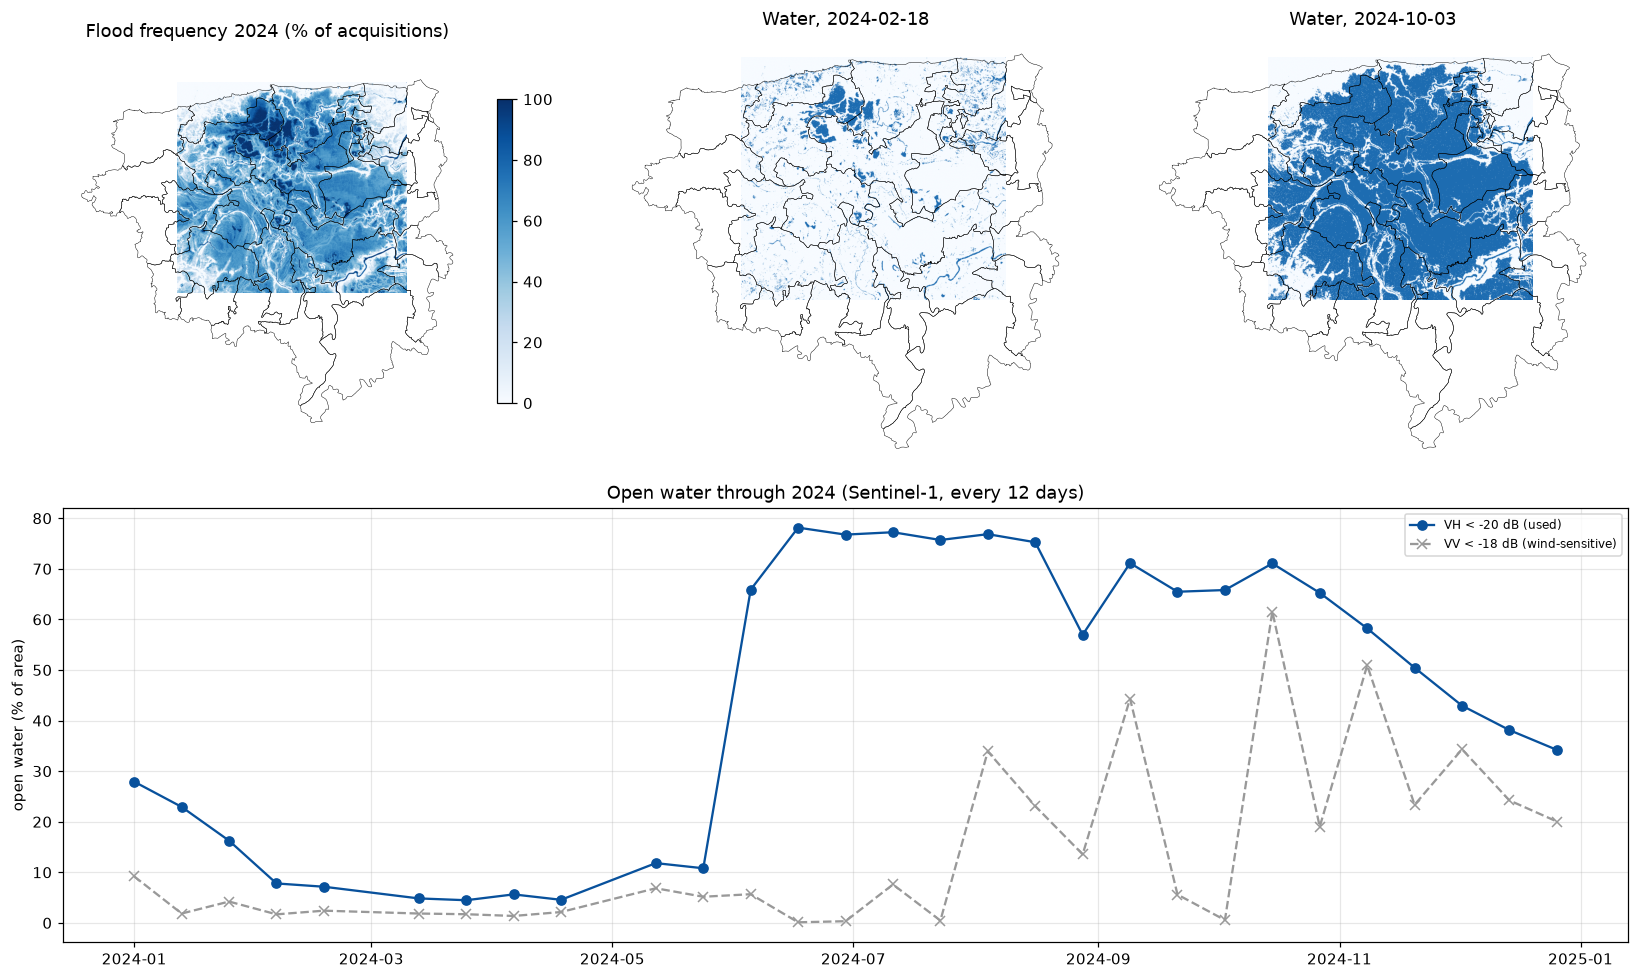

In [6]:
# Map flood frequency, dry/wet water masks, and the AOI open-water time series
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3)
ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1]); ax2 = fig.add_subplot(gs[0, 2]); ax3 = fig.add_subplot(gs[1, :])
extent = [transform.c, transform.c + transform.a * shape[1], transform.f + transform.e * shape[0], transform.f]
im = ax0.imshow(frequency, cmap="Blues", vmin=0, vmax=100, extent=extent)
unions.to_crs(CRS).boundary.plot(ax=ax0, color="k", linewidth=0.3)
ax0.set_title("Flood frequency 2024 (% of acquisitions)"); ax0.set_axis_off(); fig.colorbar(im, ax=ax0, shrink=0.7)
for a, k, title in [(ax1, dates.index(dry), f"Water, {dry}"), (ax2, dates.index(wet), f"Water, {wet}")]:
    a.imshow(np.where(valid[k], water[k], np.nan), cmap="Blues", vmin=0, vmax=1.3, extent=extent)
    unions.to_crs(CRS).boundary.plot(ax=a, color="k", linewidth=0.3); a.set_title(title); a.set_axis_off()
ax3.plot(aoi_water.index, aoi_water.values, "o-", color="#08519c", label=f"VH < {THRESHOLD_DB:g} dB (used)")
ax3.plot(rules.index, rules.vv_water_pct, "x--", color="#999999", label=f"VV < {VV_THRESHOLD_DB:g} dB (wind-sensitive)")
ax3.legend(fontsize=8)
ax3.set_ylabel("open water (% of area)"); ax3.set_title(f"Open water through {YEAR} (Sentinel-1, every 12 days)")
ax3.grid(alpha=0.3)
plt.tight_layout(); plt.show()


Processing the 29 dates took 294 s, network reads included. The rerun skipped every date in no
time, which is the property a scheduled job needs. The 29 water maps total 2.0 MB as COGs.

The two rules over the monsoon (June to October):

| Rule | Water share | Mean change between acquisitions | Median backscatter |
|---|---|---|---|
| VV < −18 dB | 0.1% to 61.5% | 21.0 points | −19.8 to −10.9 dB |
| VH < −20 dB | 57.0% to 78.2% | 5.7 points | −22.2 to −21.0 dB |

The VV jumps are not floods coming and going every 12 days. They follow the wind, which raised the
area's median VV by up to 9 dB on some dates while median VH stayed within about 1 dB.

**The year in the haors (VH):**

- **January:** water drained from 28% of the area to 8% by early February.
- **Dry season:** 4.5-8% from February to April, mostly permanent beels and rivers.
- **Rise:** about 11% through May, then a jump to 66% by 5 June and a peak of 78.2% on 17 June,
  consistent with the early-monsoon floods reported in Sylhet division that month.
- **Monsoon:** 57-77% until mid-October.
- **Recession:** from 65% at the end of October to 34% by late December.

**Unions:** the 28 unions that intersect the area differ widely. Dakshin Sreepur, Tahirpur and
Beheli, which lie entirely inside the area, were more than half under water in 7-8 months, with
mean water shares of 55-61%. Some unions only touch the area (as little as 2% of their area
inside), and their statistics describe only that part; the table's `inside_aoi_pct` column says so.

## Validation

Two independent checks:

1. **Sentinel-2.** Notebook 08_10's monitor recorded the open-water fraction of Tanguar Haor (a
   sub-area of this AOI) from optical images. Where a Sentinel-2 observation lies within 3 days of a
   Sentinel-1 acquisition, the two estimates are compared for the same sub-area.
2. **JRC Global Surface Water** (1984-2020). Pixels that were water in most years' records should
   be water in this year's flood season, and dry-season water should fall on permanent water bodies.

In [7]:
# Compare Sentinel-1 water over Tanguar Haor with optical results from Notebook 08_10
TANGUAR = (91.02, 25.08, 91.14, 25.17)
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
win = from_bounds(*transform_bounds(4326, CRS, *TANGUAR), transform)
r0, c0 = int(win.row_off), int(win.col_off)
r1, c1 = r0 + int(win.height), c0 + int(win.width)
s1_tanguar = pd.Series([water[k, r0:r1, c0:c1][valid[k, r0:r1, c0:c1]].mean() for k in range(len(dates))],
                       index=pd.to_datetime(dates), name="Sentinel-1")
s2_path = WEB / "08_10_outputs" / "monitor_data" / "observations.parquet"
if s2_path.exists():
    s2 = pd.read_parquet(s2_path)
    s2 = s2[(s2["flags"] == "") & (s2.clear_fraction >= 0.8)].set_index("date").water_fraction
    # Pair dates within 3 days and report correlation and bias
    pairs = []
    for d, v in s2.items():
        k = int(np.argmin(np.abs(s1_tanguar.index - d)))
        if abs((s1_tanguar.index[k] - d).days) <= 3:
            pairs.append({"Sentinel-2 date": d.date(), "Sentinel-1 date": s1_tanguar.index[k].date(),
                          "Sentinel-2 water": v, "Sentinel-1 water": s1_tanguar.iloc[k]})
    pairs = pd.DataFrame(pairs)
    assert len(pairs) >= 3, "too few matching dates for a comparison"
    r = np.corrcoef(pairs["Sentinel-2 water"], pairs["Sentinel-1 water"])[0, 1]
    bias = (pairs["Sentinel-1 water"] - pairs["Sentinel-2 water"]).mean()
    display(pairs.round(3))
    print(f"{len(pairs)} pairs within 3 days: correlation {r:.2f}, mean difference (S1 - S2) {bias:+.3f}")
else:
    pairs = None
    print("Run Notebook 08_10 first for the Sentinel-2 comparison.")


,Sentinel-2 date,Sentinel-1 date,Sentinel-2 water,Sentinel-1 water
0,2024-01-01,2024-01-01,0.313,0.462
1,2024-03-11,2024-03-13,0.081,0.176
2,2024-03-16,2024-03-13,0.068,0.176
3,2024-04-15,2024-04-18,0.106,0.201
4,2024-05-25,2024-05-24,0.501,0.416
5,2024-11-11,2024-11-08,0.849,0.803
6,2024-12-01,2024-12-02,0.690,0.640
7,2024-12-11,2024-12-14,0.615,0.581
8,2024-12-16,2024-12-14,0.558,0.581
9,2024-12-26,2024-12-26,0.515,0.514


10 pairs within 3 days: correlation 0.98, mean difference (S1 - S2) +0.026


In [8]:
# Cross-check 2024 water maps against long-term JRC Global Surface Water occurrence
jrc_items = list(pcc.search(collections=["jrc-gsw"], bbox=list(AOI)).items())
jrc = odc.stac.load(jrc_items, bands=["occurrence"], bbox=list(AOI), crs=CRS, resolution=RES, resampling="nearest").occurrence.isel(time=0).values.astype("float32")
jrc[jrc > 100] = np.nan
classes = pd.cut(jrc.ravel(), [-0.1, 0, 25, 75, 100], labels=["never water (0 %)", "rarely (1-25 %)", "often (26-75 %)", "mostly (76-100 %)"])
check = pd.DataFrame({"JRC occurrence": classes, "dry": np.where(valid[dates.index(dry)], water[dates.index(dry)], np.nan).ravel(),
                      "flood": np.where(valid[dates.index(wet)], water[dates.index(wet)], np.nan).ravel(),
                      "2024 frequency": frequency.ravel()})
table = check.groupby("JRC occurrence", observed=True).agg(pixels=("dry", "size"), water_dry=("dry", "mean"),
                                                           water_flood=("flood", "mean"), mean_frequency=("2024 frequency", "mean"))
table["share of area"] = table.pixels / table.pixels.sum()
table[["water_dry", "water_flood", "share of area"]] *= 100
table.round(1)


,pixels,water_dry,water_flood,mean_frequency,share of area
JRC occurrence,,,,,
never water (0 %),142119,6.0,0.3,2.800000,14.8
rarely (1-25 %),162768,6.3,21.0,21.200001,17.0
often (26-75 %),528422,1.9,90.1,54.299999,55.1
mostly (76-100 %),126265,31.6,95.9,76.199997,13.2


**Sentinel-2.** Ten Sentinel-2 observations of Tanguar Haor had a Sentinel-1 acquisition within 3
days. The two agree closely: correlation 0.98 and a mean difference of +0.026.

- From May to December the radar values are within 0.09 of the optical ones, mostly within 0.01-0.05.
- In the dry season radar sees more water: 0.18-0.20 against 0.07-0.11 in March and April, and 0.46
  against 0.31 on 1 January. The likely causes are wet bare soil and smooth harvested or flooded
  paddies, which are dark in VH. In January, receding water under emergent vegetation is classed
  differently by the two sensors.

**JRC Global Surface Water.**

| JRC 1984-2020 occurrence | Water on 3 October 2024 (flood) | Water on 18 February 2024 (dry) |
|---|---|---|
| Often water (26-75%) | 90.1% | 1.9% |
| Mostly water (76-100%) | 95.9% | 31.6% |
| Never water | 0.3% | 6.0% |

The flood-season map agrees with the long-term record. The 6% of never-water land classed as water
in February is the dry-season false-positive rate of the VH rule. It is small for flood mapping but
matters for exact dry-season areas, where Sentinel-2 is the better source (Notebook 08_10).

## Storage: COGs, GeoParquet and a STAC catalogue

The products are written in the cloud-native formats of Notebooks 08_01 and 08_02, and described in
a STAC catalogue so that any STAC client can find them by place and date.

In [9]:
# Persist union tables and build a self-contained STAC catalogue of water COGs
write_geoparquet(OUT / "unions_flood.parquet", unions)
series.to_parquet(OUT / "union_series.parquet", index=False)
print(web.geoparquet_info(OUT / "unions_flood.parquet"))

catalog = pystac.Catalog(id="haor-flood-2024", description=f"Sentinel-1 open-water maps of the Sunamganj haors, {YEAR} (GeoLattice Notebook 08_11)")
coll = pystac.Collection(
    id="haor-water", description="Open water from Sentinel-1 RTC VH < -20 dB, 30 m, every 12 days",
    extent=pystac.Extent(pystac.SpatialExtent([list(AOI)]),
                         pystac.TemporalExtent([[datetime(YEAR, 1, 1, tzinfo=timezone.utc), datetime(YEAR, 12, 31, tzinfo=timezone.utc)]])),
    license="CC-BY-4.0", providers=[pystac.Provider("Contains modified Copernicus Sentinel data, via Microsoft Planetary Computer", roles=["producer"])])
catalog.add_child(coll)
for day, p, k in zip(dates, cogs, range(len(dates))):
    item = pystac.Item(id=f"water-{day}", geometry=shapely.geometry.mapping(shapely.box(*AOI)), bbox=list(AOI),
                       datetime=datetime(day.year, day.month, day.day, tzinfo=timezone.utc),
                       properties={"water_pct": round(float(aoi_water.iloc[k]), 2), "sar:polarizations": ["VH"],
                                   "sat:relative_orbit": TRACK, "processing:threshold_db": THRESHOLD_DB,
                                   "source_items": [i.id for i in by_day[day]]})
    item.add_asset("water", pystac.Asset(href=f"../../water/{p.name}", media_type=pystac.MediaType.COG, roles=["data"],
                                         title="1 = water, 0 = land, 255 = no data"))
    coll.add_item(item)
catalog.normalize_hrefs(str((OUT / "stac").resolve()))
catalog.save(catalog_type=pystac.CatalogType.SELF_CONTAINED)
n_items = len(list(catalog.get_items(recursive=True)))
try:
    validated = catalog.validate_all()
    print(f"STAC catalogue: {n_items} items, {validated} objects validated against the STAC schemas")
except Exception as exc:
    print(f"STAC catalogue: {n_items} items written (schema validation not run: {type(exc).__name__})")
# Fix asset hrefs to be relative to each item file (catalogue is self-contained and portable)
for item_file in (OUT / "stac").rglob("water-*.json"):
    d = json.loads(item_file.read_text()); d["assets"]["water"]["href"] = f"../../../water/{Path(d['assets']['water']['href']).name}"
    item_file.write_text(json.dumps(d, indent=1))
first = next((OUT / "stac").rglob("water-*.json"))
print("example item:", first.relative_to(OUT), "->", json.loads(first.read_text())["assets"]["water"]["href"],
      "| resolves:", (first.parent / json.loads(first.read_text())["assets"]["water"]["href"]).resolve().exists())
pd.DataFrame([{"product": p.relative_to(OUT).parts[0] if p.parent != OUT else p.name, "bytes": p.stat().st_size}
              for p in OUT.rglob("*") if p.is_file()]).groupby("product").bytes.agg(["count", "sum"]).assign(MB=lambda t: (t["sum"] / 1e6).round(2))


{'version': '1.1.0', 'primary_column': 'geometry', 'encoding': 'WKB', 'crs': <Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich
, 'bbox': [90.82261064500005, 24.79260454100006, 91.31413922900003, 25.20736202200004], 'geometry_types': ['MultiPolygon', 'Polygon'], 'covering': True, 'num_rows': 28, 'num_row_groups': 1, 'columns': ['ADM4_EN', 'ADM4_PCODE', 'ADM3_EN', 'ADM2_EN', 'geometry', 'water_min', 'water_max', 'water_mean', 'months_over_50pct', 'peak_date', 'inside_aoi_pct', 'bbox']}
STAC catalogue: 29 items, 29 objects validated against the STAC schemas
example item: stac/haor-water/water-2024-03-13/water-2024-03-13.json -> ../../../water/water_2024-03-13.tif | resolves: True


,count,sum,MB
product,,,
flood_frequency.tif,1,1288628,1.29
stac,31,42764,0.04
union_series.parquet,1,10780,0.01
unions_flood.parquet,1,919951,0.92
water,58,2051467,2.05


All products together take about 4.3 MB:

- 29 water COGs, each with a JSON sidecar (2.05 MB);
- the flood-frequency COG (1.3 MB);
- unions with their statistics as GeoParquet 1.1, with a bbox covering column (0.9 MB);
- the long table of union water shares by date (11 kB);
- a STAC catalogue of 29 items (43 kB).

All 29 STAC items validated against the STAC schemas. Each item's asset link is relative and
resolves to its COG, so the folder can be copied to any static host or bucket as is.

## The service: FastAPI with OGC endpoints, tiles and a web map

One FastAPI application serves everything. `geolattice.web.create_app` provides the standard parts
(XYZ tiles of the flood frequency and the latest water map, OGC API: Features for the unions),
mounted at `/ogc`. Custom endpoints under `/api` answer the questions the dashboard asks. A web page
at `/map` combines both, and the STAC catalogue is published as static files at `/stac`.

In [10]:
# Assemble the FastAPI app: OGC tiles/features plus custom flood statistics routes
latest = cogs[-1]
UNIONS = read_geoparquet(OUT / "unions_flood.parquet")
SERIES = pd.read_parquet(OUT / "union_series.parquet")
NAMES = {n.lower(): c for n, c in zip(UNIONS.ADM4_EN, UNIONS.ADM4_PCODE)}

app = FastAPI(title="Haor Flood Monitor", version="1.0.0",
              description=f"Sentinel-1 open water in the Sunamganj haors, {YEAR}: tiles, OGC API Features and statistics.")
app.add_middleware(GZipMiddleware, minimum_size=1000)
ogc = web.create_app(
    rasters={"flood_frequency": {"path": OUT / "flood_frequency.tif", "colormap": "Blues", "rescale": (0, 100)},
             "water_latest": {"path": latest, "colormap": "Blues", "rescale": (0, 1.3), "nodata": 255}},
    vectors={"unions": UNIONS[["ADM4_EN", "ADM4_PCODE", "ADM3_EN", "water_min", "water_max", "water_mean",
                               "months_over_50pct", "peak_date", "geometry"]]},
    title="Haor Flood Monitor: OGC API")
app.mount("/ogc", ogc)

@app.get("/api/dates", tags=["api"])
def list_dates():
    "Acquisition dates with the open-water share of the whole area."
    return [{"date": str(d.date()), "water_pct": round(float(v), 2)} for d, v in aoi_water.items()]

@app.get("/api/unions/{name}", tags=["api"])
def union_series(name: str):
    "Water share of one union on every date, and its summary."
    code_ = NAMES.get(name.lower()) or (name if name in set(UNIONS.ADM4_PCODE) else None)
    if code_ is None:
        raise HTTPException(404, {"message": f"No union {name!r} in the monitored area",
                                  "suggestions": difflib.get_close_matches(name.title(), list(UNIONS.ADM4_EN), 3, 0.6)})
    row = UNIONS[UNIONS.ADM4_PCODE == code_].iloc[0]
    s = SERIES[SERIES.ADM4_PCODE == code_].sort_values("date")
    return {"union": row.ADM4_EN, "pcode": code_, "upazila": row.ADM3_EN, "summary": {
                k: (None if pd.isna(row[k]) else (row[k].item() if hasattr(row[k], "item") else row[k]))
                for k in ["water_min", "water_max", "water_mean", "months_over_50pct", "peak_date"]},
            "series": [{"date": str(d.date()), "water_pct": None if pd.isna(v) else round(float(v), 1)}
                       for d, v in zip(s.date, s.water_pct)]}

@app.get("/api/rank", tags=["api"])
def rank(date: str = Query(..., description="Acquisition date YYYY-MM-DD"), limit: int = Query(10, ge=1, le=100)):
    "The most flooded unions on one acquisition date."
    try:
        when = pd.Timestamp(date)
    except ValueError:
        raise HTTPException(422, f"Not a valid date: {date!r} (use YYYY-MM-DD)") from None
    s = SERIES[SERIES.date == when]
    if s.empty:
        raise HTTPException(404, f"No acquisition on {date}; see /api/dates")
    top = s.nlargest(limit, "water_pct").merge(UNIONS[["ADM4_PCODE", "ADM4_EN", "ADM3_EN"]], on="ADM4_PCODE")
    return [{"union": r.ADM4_EN, "upazila": r.ADM3_EN, "water_pct": round(float(r.water_pct), 1)} for r in top.itertuples()]

app.mount("/stac", StaticFiles(directory=OUT, html=False), name="stac")     # serves stac/ and water/ for STAC clients


In [11]:
# Leaflet map HTML that consumes OGC tiles and the union time-series API
MAP = '''<!DOCTYPE html><html><head><meta charset="utf-8"><title>Haor Flood Monitor</title>
<meta name="viewport" content="width=device-width, initial-scale=1">
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<style>html,body,#map{height:100%;margin:0;font:13px sans-serif}.panel{position:absolute;z-index:999;top:10px;right:10px;
background:#fff;padding:8px 10px;border-radius:6px;box-shadow:0 1px 5px #0004;max-width:300px}</style></head>
<body><div id="map"></div><div class="panel"><b>Haor Flood Monitor 2024</b><br>
<label><input type="radio" name="l" value="flood_frequency" checked> flood frequency (% of dates)</label><br>
<label><input type="radio" name="l" value="water_latest"> water, latest acquisition</label><br>
<span id="info">Click a union for its 2024 water series.</span></div><script>
const map = L.map("map").setView([25.07, 91.10], 11);
L.tileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
            {attribution: "Imagery &copy; Esri; water: Copernicus Sentinel-1 via Planetary Computer"}).addTo(map);
let raster = L.tileLayer("../ogc/tiles/flood_frequency/{z}/{x}/{y}.png", {opacity: 0.75, maxNativeZoom: 13}).addTo(map);
document.querySelectorAll("input[name=l]").forEach(r => r.onchange = () => {
  raster.setUrl(`../ogc/tiles/${r.value}/{z}/{x}/{y}.png`); });
function spark(series) {
  const w = 260, h = 70, n = series.length;
  const pts = series.map((s, i) => `${(i / (n - 1) * w).toFixed(1)},${(h - (s.water_pct ?? 0) / 100 * h).toFixed(1)}`).join(" ");
  return `<svg width="${w}" height="${h + 14}"><rect width="${w}" height="${h}" fill="#f2f6fa"/>
    <polyline points="${pts}" fill="none" stroke="#08519c" stroke-width="1.5"/>
    <text x="0" y="${h + 12}" font-size="10">${series[0].date}</text>
    <text x="${w}" y="${h + 12}" font-size="10" text-anchor="end">${series[n - 1].date}</text></svg>`;
}
fetch("../ogc/collections/unions/items?limit=1000").then(r => r.json()).then(fc => L.geoJSON(fc, {
  style: {color: "#ffffff", weight: 0.8, fillOpacity: 0},
  onEachFeature: (f, layer) => layer.on("click", async e => {
    const d = await (await fetch(`../api/unions/${f.properties.ADM4_PCODE}`)).json();
    const s = d.summary;
    L.popup().setLatLng(e.latlng).setContent(`<b>${d.union}</b>, ${d.upazila}<br>water ${s.water_min}-${s.water_max} %
      (mean ${s.water_mean} %), peak ${s.peak_date}<br>months over 50 %: ${s.months_over_50pct}<br>${spark(d.series)}`).openOn(map);
  })}).addTo(map));
</script></body></html>'''

@app.get("/map", response_class=HTMLResponse, include_in_schema=False)
def web_map():
    return MAP

# Start the local server and embed the map in the notebook
server = web.start_server(app)
print(server)
display(IFrame(server.url + "/map", width="100%", height=560))


BackgroundServer(http://127.0.0.1:34771)


The map is served by this notebook's kernel and works while the kernel runs: switch between the
flood-frequency and latest-water layers, and click a union for its 2024 water series. The same
service answers programs:

In [12]:
# Smoke-test key API, OGC, STAC, and tile endpoints over HTTP
import httpx
api = httpx.Client(base_url=server.url, timeout=60)
peak_day = str(aoi_water.idxmax().date())
checks = {
    "/api/dates": api.get("/api/dates"),
    f"/api/rank?date={peak_day}&limit=5": api.get("/api/rank", params={"date": peak_day, "limit": 5}),
    "/api/unions/Uttar Sreepur": api.get("/api/unions/Uttar Sreepur"),
    "/ogc/collections/unions/items?limit=2": api.get("/ogc/collections/unions/items", params={"limit": 2}),
    "/ogc/tiles/flood_frequency/tilejson.json": api.get("/ogc/tiles/flood_frequency/tilejson.json"),
    "/stac/stac/catalog.json": api.get("/stac/stac/catalog.json"),
    "/openapi.json": api.get("/openapi.json"),
}
display(pd.DataFrame([{"request": k, "status": r.status_code, "type": r.headers.get("content-type", "").split(";")[0],
                       "bytes": len(r.content)} for k, r in checks.items()]))
print("most flooded unions on", peak_day, ":", checks[f"/api/rank?date={peak_day}&limit=5"].json())
u = checks["/api/unions/Uttar Sreepur"]
print("Uttar Sreepur:", u.json()["summary"] if u.status_code == 200 else u.json())
t = web.lonlat_to_tile(91.10, 25.10, 12)
tile = api.get(f"/ogc/tiles/flood_frequency/{t.z}/{t.x}/{t.y}.png")
print("tile", f"{t.z}/{t.x}/{t.y}", tile.status_code, tile.headers.get("content-type"), len(tile.content), "bytes")


,request,status,type,bytes
0,/api/dates,200,application/json,1153
1,/api/rank?date=2024-06-17&limit=5,200,application/json,334
2,/api/unions/Uttar Sreepur,200,application/json,1315
3,/ogc/collections/unions/items?limit=2,200,application/geo+json,170575
4,/ogc/tiles/flood_frequency/tilejson.json,200,application/json,263
5,/stac/stac/catalog.json,200,application/json,406
6,/openapi.json,200,application/json,2297


most flooded unions on 2024-06-17 : [{'union': 'Dharmapasha', 'upazila': 'Dharampasha', 'water_pct': 98.5}, {'union': 'Bara Kharpan', 'upazila': 'Kalmakanda', 'water_pct': 98.4}, {'union': 'Dakshin  Sukhairrajapur', 'upazila': 'Dharampasha', 'water_pct': 95.8}, {'union': 'Fenarbak', 'upazila': 'Jamalganj', 'water_pct': 94.1}, {'union': 'Dakshin Sreepur', 'upazila': 'Tahirpur', 'water_pct': 93.9}]
Uttar Sreepur: {'water_min': 3.8, 'water_max': 80.7, 'water_mean': 50.1, 'months_over_50pct': 7, 'peak_date': '2024-06-17'}
tile 12/3084/1752 200 image/png 130126 bytes


Every request succeeded:

- **The custom API:** the dates with the area's water share, the five most flooded unions at the
  17 June peak (Dharmapasha and Bara Kharpan at about 98%), and the full series of Uttar Sreepur
  (water 3.8-80.7%, 7 months over half flooded, peak on 17 June).
- **The mounted OGC service:** conformance, union features and TileJSON.
- **A PNG tile** of the flood frequency (130 kB at zoom 12).
- **The STAC catalogue,** and the OpenAPI description of the whole service.

The web map was checked in a browser. The flood-frequency tiles draw over satellite imagery with
the union outlines, and clicking Uttar Sreepur fetched its series from `/api` and drew it in the
popup.

## Tests and operations

The service's promises, as tests (Notebook 08_06 style), run against the app without a network:

In [13]:
# In-notebook regression tests for API behaviour, OGC mounts, and COG products
tc = TestClient(app)
def test_dates_cover_the_year():
    d = tc.get("/api/dates").json()
    assert len(d) == len(dates) and d[0]["date"].startswith(str(YEAR)) and all(0 <= x["water_pct"] <= 100 for x in d)
def test_union_lookup_by_name_and_code_and_suggestions():
    code_ = UNIONS.ADM4_PCODE.iloc[0]
    assert tc.get(f"/api/unions/{code_}").status_code == 200
    assert tc.get(f"/api/unions/{UNIONS.ADM4_EN.iloc[0].upper()}").status_code == 200
    r = tc.get("/api/unions/Uttar Sripur")
    assert r.status_code == 404 and r.json()["detail"]["suggestions"]
def test_series_matches_stored_table():
    code_ = UNIONS.ADM4_PCODE.iloc[0]
    got = [x["water_pct"] for x in tc.get(f"/api/unions/{code_}").json()["series"]]
    want = SERIES[SERIES.ADM4_PCODE == code_].sort_values("date").water_pct.round(1).tolist()
    assert np.allclose(np.array(got, float), np.array(want, float), equal_nan=True)
def test_rank_is_sorted_and_validates_dates():
    r = tc.get("/api/rank", params={"date": peak_day, "limit": 10}).json()
    assert [x["water_pct"] for x in r] == sorted([x["water_pct"] for x in r], reverse=True)
    assert tc.get("/api/rank", params={"date": "2024-02-30"}).status_code in (404, 422)
def test_ogc_and_tiles_work_under_the_mount():
    assert tc.get("/ogc/conformance").status_code == 200
    assert tc.get("/ogc/collections/unions/items", params={"limit": 3}).json()["numberReturned"] == 3
    assert tc.get(f"/ogc/tiles/flood_frequency/{t.z}/{t.x}/{t.y}.png").status_code == 200
def test_processing_is_idempotent():
    assert all(process_day(d) == "skipped" for d in dates[:3])
def test_products_are_valid_cogs():
    assert web.validate_cog(OUT / "flood_frequency.tif").valid and web.validate_cog(cogs[0]).valid

results = []
for name, f in [(n, f) for n, f in list(globals().items()) if n.startswith("test_") and callable(f)]:
    try:
        f(); results.append((name, "PASS", ""))
    except Exception as exc:
        results.append((name, "FAIL", f"{type(exc).__name__}: {exc}"))
pd.DataFrame(results, columns=["test", "result", "error"])


,test,result,error
0,test_dates_cover_the_year,PASS,
1,test_union_lookup_by_name_and_code_and_suggest...,PASS,
2,test_series_matches_stored_table,PASS,
3,test_rank_is_sorted_and_validates_dates,PASS,
4,test_ogc_and_tiles_work_under_the_mount,PASS,
5,test_processing_is_idempotent,PASS,
6,test_products_are_valid_cogs,PASS,


**Operating the system.** The pieces from Notebook 08_10 apply directly:

| Concern | How |
|---|---|
| Updates | Run the processing (Sections 5-8) on a schedule after each Sentinel-1 acquisition (every 12 days on one track); `process_day` skips existing dates |
| Packaging | Processing and service as two container images sharing the product storage |
| Storage | COGs, GeoParquet and STAC in object storage (S3, Azure Blob); the service reads them over HTTP with range requests (Notebook 08_02) |
| Serving | `uvicorn app:app --workers 4` behind HTTPS (Notebook 08_05), a CDN in front of tiles |
| Quality | The tests above in CI; alert when an update fails or when water shares jump implausibly |
| Cost | Processing a year here took minutes on one machine; a scheduled container on a small VM or a batch job costs cents per run (Notebook 08_08) |

In [14]:
# Shut down the demo server and list the products left on disk
server.stop()
print("service stopped; products in", OUT)
print(sorted(p.name for p in OUT.iterdir()))


service stopped; products in ../../../data/data_web_cloud_gis/08_11_outputs
['flood_frequency.tif', 'stac', 'union_series.parquet', 'unions_flood.parquet', 'water']


## Summary: from data to decisions

The capstone joined the module's parts into one working system for the Sunamganj haors in 2024:

- **Data:** 29 Sentinel-1 RTC acquisitions found through STAC and read lazily with odc-stac (08_09).
- **Method:** a water rule chosen by evidence. VH < −20 dB was stable through the monsoon, while the
  common VV rule swung between 0.1% and 61.5% with the wind.
- **Results:**
  - water rose from 4.5% of the area in March to 78.2% on 17 June;
  - it stayed above 57% until October and receded to 34% by December;
  - three fully covered unions were more than half under water in 7-8 months.
- **Validation:** correlation 0.98 with Sentinel-2 (08_10), and agreement with 37 years of JRC
  water records. The known bias is about 6% false water on dry land in the dry season.
- **Products:** COGs, GeoParquet and a validated STAC catalogue (08_01, 08_02), 4.3 MB in total.
- **Service:** FastAPI with `geolattice.web` tiles and OGC API: Features (08_05, 08_06), and a web map
  calling the API (08_04, 08_07).
- **Operations:** idempotent processing and seven passing service tests (08_10).

**What the system adds beyond a map.** Officers can see which unions flood first and longest, and
when; researchers can pull the union series as GeoParquet or through OGC API: Features into their
own tools; any STAC client can find the water maps by place and date; and the whole chain reruns
itself as new radar images arrive.

**Limitations to state with the results.**

- A single threshold misses water under vegetation (flooded rice and reeds can scatter strongly) and
  can mistake smooth dry surfaces and radar shadow for water.
- VH water sits close to the sensor's noise floor; the threshold (−20 dB) is tuned to this area and
  season and should be re-checked elsewhere.
- Wind roughens open water. It made the common VV rule unusable here; VH is far less affected but
  not immune.
- 30 m pixels blur narrow channels.
- Union statistics are only as good as the boundaries.

**Exercises**

1. Replace the fixed VH threshold by an automatic one per date (Otsu's method on the dB histogram)
   and compare the water series and the validation of Section 7.
2. Add the descending track (relative orbit 150) to double the time resolution. What must you check
   before mixing tracks?
3. Detect *early flash floods*: unions whose water share rises by more than 20 points between two
   acquisitions in March-May, when Boro rice is still in the field. Add an `/api/alerts` endpoint.
4. Add Sentinel-2 NDVI of the cropland (Notebook 08_10's monitor) to the union popups.
5. Package the processing as a `haor_monitor`-style project with tests, a Dockerfile and a schedule,
   and the service as a second image; write a `compose.yaml` that runs both.

**References**

- Twele, A., Cao, W., Plank, S. & Martinis, S. (2016). Sentinel-1-based flood mapping: a fully automated processing chain. *International Journal of Remote Sensing*, 37(13), 2990-3004.
- Uddin, K., Matin, M. A. & Meyer, F. J. (2019). Operational flood mapping using multi-temporal Sentinel-1 SAR images: a case study from Bangladesh. *Remote Sensing*, 11(13), 1581.
- Pekel, J.-F. et al. (2016). High-resolution mapping of global surface water and its long-term changes. *Nature*, 540, 418-422.
- Microsoft Planetary Computer: Sentinel-1 RTC. https://planetarycomputer.microsoft.com/dataset/sentinel-1-rtc
- STAC specification. https://stacspec.org